# Uso de IA y entorno universitario: análisis exploratorio
**Sistemas Inteligentes · Matemáticas Aplicadas y Computación (MAC)**

Este notebook reúne dos cuestionarios para describir cómo se usa la IA y explorar el entorno donde se estudia. Parte de los archivos originales, muestra qué se limpió en Python y presenta el análisis exploratorio y sus KPIs. Después prueba dos técnicas de búsqueda de hiperparámetros en K-Means y KNN. La regresión complementa el estudio con una estimación de las horas diarias de IA.

Los cuestionarios recogen experiencias y percepciones. Las calificaciones verificadas y las mediciones de aprendizaje quedan fuera del alcance de las fuentes.

El análisis vive en `analisis.py` y la limpieza por pregunta, en `limpieza_encuestas.py`. Para ejecutar el notebook se usa `requirements-dev.txt`. Las fuentes originales se leen desde `data/private/` o la ruta indicada en `IA_DATA_DIR`. Los agregados se escriben en `resultados/` o en `IA_RESULTS_DIR`. Las salidas contienen conteos, estadísticas y métricas del grupo.

## 1. Carga, validación e integración
Antes de unir las fuentes se comprueba que las preguntas tengan el esquema esperado y que las claves sean únicas. El cruce permite saber cuántas personas respondieron ambos cuestionarios. Las fuentes originales se conservan sin cambios.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image, Markdown
from analisis import analizar, exportar

ROOT = Path.cwd()
DATA_DIR = Path(os.environ.get("IA_DATA_DIR", str(ROOT / "data" / "private")))
OUT = Path(os.environ.get("IA_RESULTS_DIR", str(ROOT / "resultados")))
resultado = analizar(DATA_DIR)
exportar(resultado, OUT)
r = resultado.resumen
display(pd.DataFrame([r["muestra"]]))

,ia,bienestar,emparejados,solo_ia,solo_bienestar
0,24,19,19,5,0


## 2. Limpieza en Python y datos ausentes
La tabla enumera **todas las columnas del formulario propio** y las variables del formulario adicional que se usaron. Las cuentas se validan con una expresión regular y se comprueba su unicidad antes de unir las fuentes. La fecha y la hora se convierten a un formato común. En las respuestas abiertas se normalizan espacios y caracteres de escritura conservando el sentido de lo que contestó cada persona.

Las expresiones regulares reconocen unidades y variantes de «Chat GPT». La similitud de cadenas se reserva para posibles erratas en un nombre aislado, como «Geminni» en un ejemplo inventado. Se acepta una variante únicamente si se parece mucho a un nombre del catálogo y la segunda opción queda claramente por debajo. Las horas, la edad, el traslado y los semestres se convierten a unidades comparables. Las preguntas de bienestar fuera del alcance se listan por separado.

Las columnas «Sin dato al leer» y «Sin dato tras limpiar» cuentan celdas vacías o inválidas según la etapa. «Normalizadas» indica cambios de representación en esta primera etapa. La revisión inferior cuenta valores que quedaron sin convertir al aplicar las reglas de tipo y unidades. Las cinco personas que solo respondieron el formulario de IA conservan su entorno como faltante. La imputación KNN del ejercicio de clasificación se ajusta dentro de cada entrenamiento. La regresión usa los casos completos de sus dos predictores y su objetivo.

In [2]:
for fuente, titulo in (("ia", "Uso de IA"), ("bienestar", "Entorno y bienestar")):
    auditoria = r["limpieza"][fuente]
    print(f"{titulo} · {auditoria['filas']} respuestas · {auditoria['columnas_cubiertas']} columnas tratadas")
    display(pd.DataFrame(auditoria["columnas"]).rename(columns={
        "campo": "Campo",
        "tratamiento": "Tratamiento",
        "ausentes_origen": "Sin dato al leer",
        "ausentes_limpios": "Sin dato tras limpiar",
        "modificados": "Normalizadas",
    }))
    if fuente == "bienestar":
        print("Campos fuera del alcance:", ", ".join(auditoria["columnas_fuera_de_alcance"]))

display(pd.DataFrame.from_dict(r["calidad"]["numericas_ia_sin_parsear"], orient="index", columns=["Sin convertir (IA)"]))
display(pd.DataFrame.from_dict(r["calidad"]["numericas_bie_sin_parsear"], orient="index", columns=["Sin convertir (entorno observado)"]))
print("Celdas vacías en preguntas de IA usadas para análisis de texto:", r["calidad"]["textos_ia_ausentes"])
print("Participantes sin encuesta de bienestar:", r["calidad"]["bienestar_no_observado"])

Uso de IA · 24 respuestas · 18 columnas tratadas


,Campo,Tratamiento,Sin dato al leer,Sin dato tras limpiar,Normalizadas
0,timestamp_ia,Conversión a fecha y hora. Entradas inválidas ...,0,0,0
1,cuenta,Clave privada validada con regex de nueve dígi...,0,0,0
2,herramientas_frecuencia,"Texto normalizado, alias por regex y similitud...",0,0,10
3,fase_estudio,"Unicode NFC, espacios y marcas explícitas de a...",0,0,7
4,cambio_estudio,"Unicode NFC, espacios y marcas explícitas de a...",0,0,11
5,proceso_verificacion,"Unicode NFC, espacios y marcas explícitas de a...",0,0,7
6,impacto_tiempo,"Unicode NFC, espacios y marcas explícitas de a...",0,0,13
7,diferencia_calificaciones,"Unicode NFC, espacios y marcas explícitas de a...",1,1,7
8,independencia_resolucion,"Unicode NFC, espacios y marcas explícitas de a...",0,0,9
9,impacto_estres,"Unicode NFC, espacios y marcas explícitas de a...",0,0,11


Entorno y bienestar · 19 respuestas · 9 columnas tratadas


,Campo,Tratamiento,Sin dato al leer,Sin dato tras limpiar,Normalizadas
0,cuenta,Clave privada validada con regex de nueve dígi...,0,0,0
1,edad_raw,Texto normalizado y conversión posterior a año...,0,0,1
2,convivencia_raw,Texto normalizado y unificación posterior en c...,0,0,3
3,traslado_raw,Texto normalizado y conversión posterior a min...,0,0,5
4,ambiente_hogar,"Unicode NFC, espacios y marcas explícitas de a...",0,0,6
5,calidad_sueno,"Unicode NFC, espacios y marcas explícitas de a...",0,0,5
6,frecuencia_desanimo,"Unicode NFC, espacios y marcas explícitas de a...",0,0,6
7,irritabilidad,"Unicode NFC, espacios y marcas explícitas de a...",0,0,8
8,dificultad_concentracion,"Unicode NFC, espacios y marcas explícitas de a...",0,0,9


Campos fuera del alcance: timestamp_bie, carrera_raw, semestre_raw, tranquilidad_estudio, apoyo_social, impacto_transporte, interes_materias, cambios_alimentacion


,Sin convertir (IA)
horas_ia_dia,0
semestre_inicio,0


,Sin convertir (entorno observado)
edad,0
traslado_min,0


Celdas vacías en preguntas de IA usadas para análisis de texto: 2
Participantes sin encuesta de bienestar: 5


## 3. Qué aparece en las respuestas abiertas
TF-IDF destaca términos con unigramas y bigramas, hasta 30 características. La polaridad léxica busca expresiones positivas y negativas por pregunta, contemplando negaciones y alivio.

La tabla permite revisar cuántas respuestas sustentan cada media y cuántas quedaron en cero. Un cero también puede indicar que el vocabulario no reconoció una señal. El indicador no es una escala de aprendizaje o salud mental; la ironía, las negaciones lejanas y la ambigüedad limitan su lectura.

,n,media,n_score_cero
fase_estudio,24.0,0.056,18.0
cambio_estudio,24.0,0.271,12.0
proceso_verificacion,24.0,0.049,22.0
impacto_tiempo,24.0,0.222,13.0
diferencia_calificaciones,23.0,0.167,14.0
independencia_resolucion,24.0,-0.031,12.0
impacto_estres,24.0,0.232,9.0
reglas_personales,24.0,0.090,17.0
pensamiento_critico,23.0,0.025,12.0
motivo_principal,24.0,0.297,11.0


Cero significa balance o falta de vocabulario coincidente; no neutralidad demostrada.


,TF-IDF medio
rapido,0.136833
tiempo,0.128883
menos,0.126045
informacion,0.117707
temas,0.117361
ayuda,0.115518
resolver,0.110384
pero,0.109541
redaccion,0.107226
investigacion,0.105673


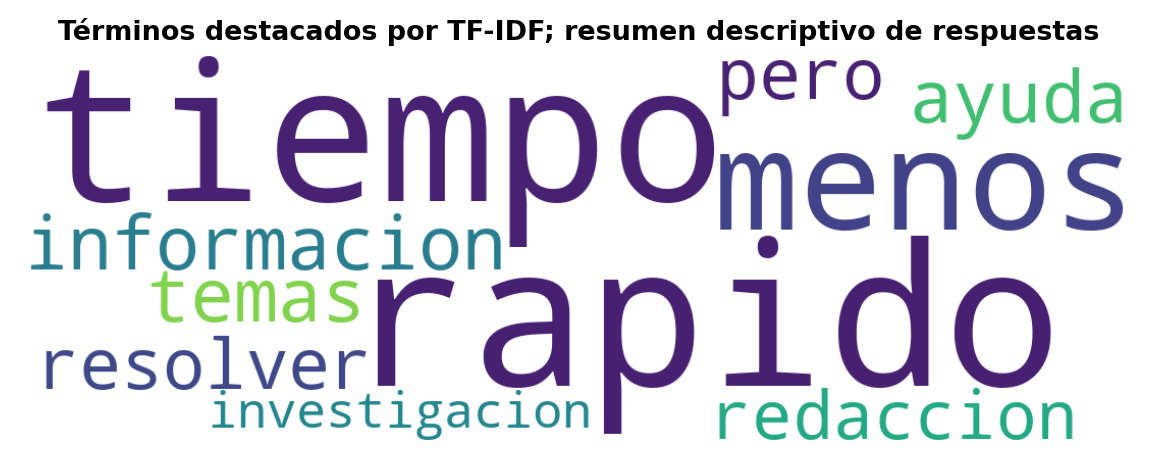

In [3]:
display(pd.DataFrame(r["polaridad_por_pregunta"]).T.round(3))
print("Cero significa balance o falta de vocabulario coincidente; no neutralidad demostrada.")
display(pd.Series(r["tfidf_top"], name="TF-IDF medio").to_frame())
display(Image(filename=str(OUT / "figuras" / "nlp.png")))

## 4. EDA y KPIs sobre hábitos de uso y entorno
Las tablas describen duraciones, herramientas y propósitos. La mediana ubica el centro de las respuestas ordenadas y ayuda a leer duraciones cuando hay valores extremos. Las categorías guía, atajo e híbrido dejan visibles las respuestas contextuales o insuficientes.

El porcentaje de uso mixto divide las respuestas híbridas entre las 24 respuestas del formulario de IA. El porcentaje de uso de varias herramientas divide, con la misma base, las respuestas que mencionan dos o más herramientas. Cada persona puede mencionar más de una herramienta. La mediana de traslado usa las 19 respuestas válidas de entorno.

,KPI,Valor,Unidad,Base
0,Mediana de uso de IA,1.50,horas al día,24
1,Modalidad mixta,54.17,%,24
2,Uso de dos o más herramientas,54.17,%,24
3,Mediana de traslado,60.00,minutos,19


,n,media,mediana,sd,min,max,q1,q3
horas_ia_dia,24.0,1.906,1.500,1.825,0.083,8.000,1.000,2.000
semestre_inicio,24.0,3.208,3.000,1.285,1.000,6.000,2.750,4.000
total_herramientas,24.0,1.750,2.000,0.847,1.000,4.000,1.000,2.000
score_beneficio_ia,24.0,0.136,0.154,0.143,-0.146,0.585,0.062,0.194
edad,19.0,22.158,22.000,1.302,21.000,25.000,21.000,23.000
traslado_min,19.0,70.526,60.000,75.699,10.000,360.000,35.000,75.000
score_bienestar,19.0,-0.002,0.000,0.134,-0.300,0.200,-0.100,0.100


,Respuestas
Híbrido,13
Guía,7
Atajo,2
Contextual,1
No clasificable,1


,Respuestas
No,11
Sí,8
Parcial / Depende,4
Indeciso,1


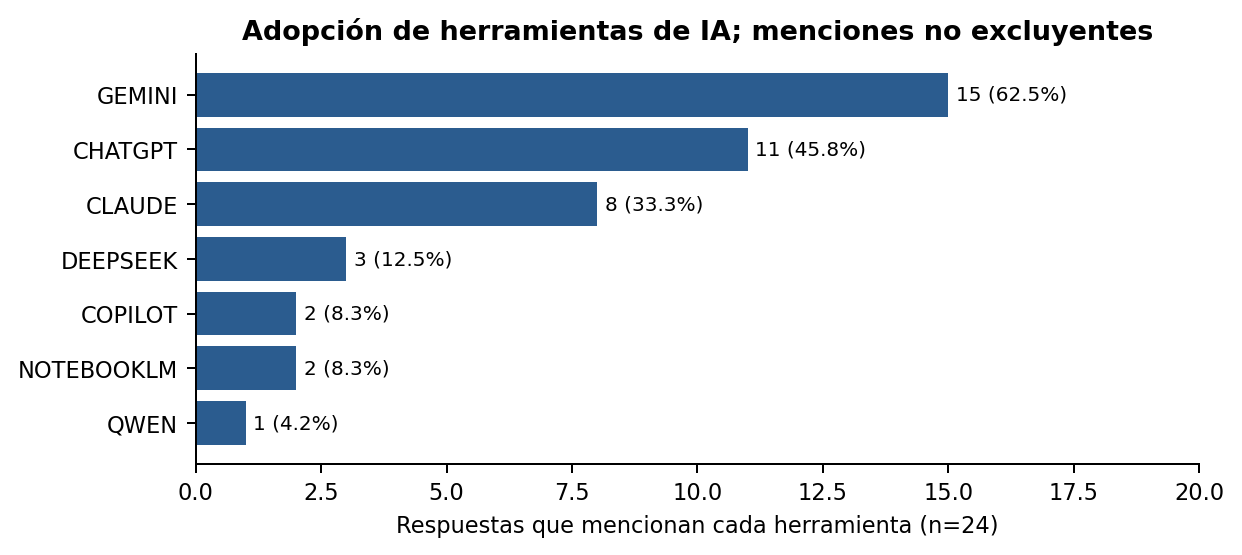

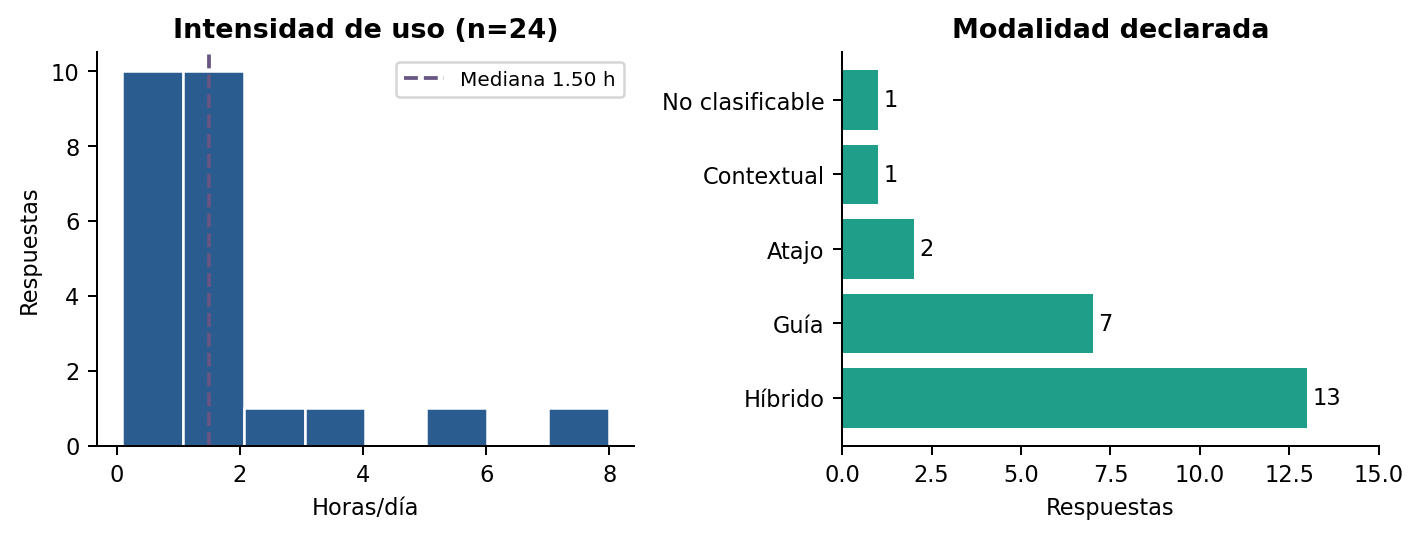

In [4]:
kpis = r["kpis"]
display(pd.DataFrame([
    {"KPI": "Mediana de uso de IA", "Valor": kpis["mediana_ia_h"], "Unidad": "horas al día",
     "Base": r["descriptivos"]["horas_ia_dia"]["n"]},
    {"KPI": "Modalidad mixta", "Valor": kpis["hibrido_pct"], "Unidad": "%",
     "Base": r["muestra"]["ia"]},
    {"KPI": "Uso de dos o más herramientas", "Valor": kpis["multiherramienta_pct"], "Unidad": "%",
     "Base": r["muestra"]["ia"]},
    {"KPI": "Mediana de traslado", "Valor": kpis["traslado_mediana_min"], "Unidad": "minutos",
     "Base": r["descriptivos"]["traslado_min"]["n"]},
]).round(2))

display(pd.DataFrame(r["descriptivos"]).T.round(3))
display(pd.Series(r["tipo_uso"], name="Respuestas").to_frame())
display(pd.Series(r["reemplazo"], name="Respuestas").to_frame())
display(Image(filename=str(OUT / "figuras" / "herramientas.png")))
display(Image(filename=str(OUT / "figuras" / "uso_modalidad.png")))

## 5. ¿Hay asociación entre traslado y uso de IA?
Spearman busca un patrón en el que una variable tienda a subir o bajar junto con otra. El cruce utiliza solo personas con ambas encuestas. Un coeficiente cercano a cero indica poca asociación monotónica observada, pero un valor p alto no demuestra que la relación no exista.

Las correlaciones son exploratorias, sin ajuste por comparaciones múltiples. No permiten concluir que el transporte cause un cambio en el uso de IA.

,n,rho,p
0,19,0.1375,0.5746


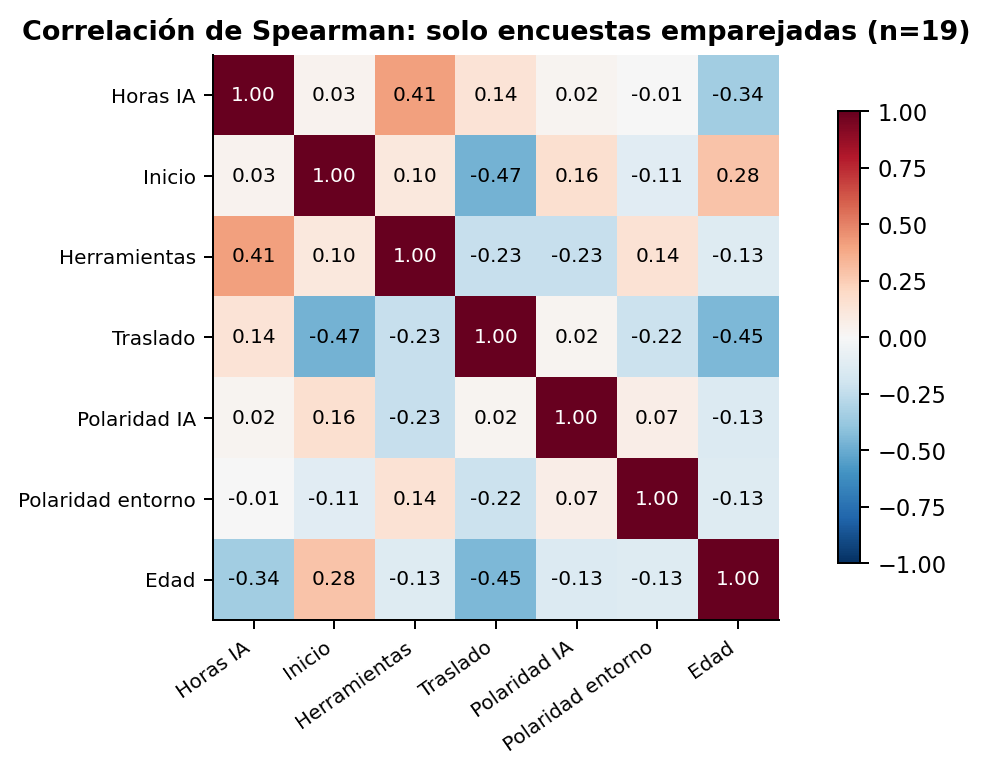

In [5]:
display(pd.DataFrame([r["correlacion_traslado_ia"]]).round(4))
display(Image(filename=str(OUT / "figuras" / "correlacion.png")))

## 6. No supervisado: K-Means y búsqueda de hiperparámetros
K-Means agrupa las respuestas según la cercanía de sus variables numéricas estandarizadas. Usa los casos con bienestar observado y variables completas. Probamos distintas cantidades de grupos y formas de inicializar sus centros. `GridSearchCV` recorre todas las combinaciones de la lista y `RandomizedSearchCV` toma una parte de esa lista con semilla 42.

En cada pliegue la escala y los centros se aprenden con las filas de entrenamiento. La silueta mide qué tan separadas quedan las filas de validación al asignarlas a esos centros. Un pliegue en el que no se puede calcular recibe −1 y se cuenta como inválido. Los tamaños de grupo y la silueta del ajuste final se calculan con toda la muestra disponible. Las siluetas descriptivas por cada valor de k y la comparación jerárquica también se calculan con toda la muestra.

Con pocas respuestas, una persona con valores muy distintos puede quedar sola en un grupo. Las agrupaciones son exploratorias. Se omiten descripciones de un grupo cuando este o su complemento tienen menos de tres personas.

,Búsqueda,Combinaciones,Configuración elegida,Silueta media,Desv. entre pliegues,Pliegues válidos
0,GridSearchCV,16,"init=k-means++, n_clusters=4, n_init=20",0.196,0.17,3/3
1,RandomizedSearchCV,8,"n_init=20, n_clusters=4, init=k-means++",0.196,0.17,3/3


Búsqueda elegida: GridSearchCV
Ajuste final: 4 grupos con 19 respuestas y silueta 0.110.
Tamaños de los grupos: 1, 12, 1, 5
Silueta descriptiva del agrupamiento jerárquico: 0.133.
Varianza resumida por los dos primeros componentes de PCA: 49.5%.


,Silueta descriptiva en la muestra completa
Grupos,
2,0.360
3,0.134
4,0.141
5,0.140


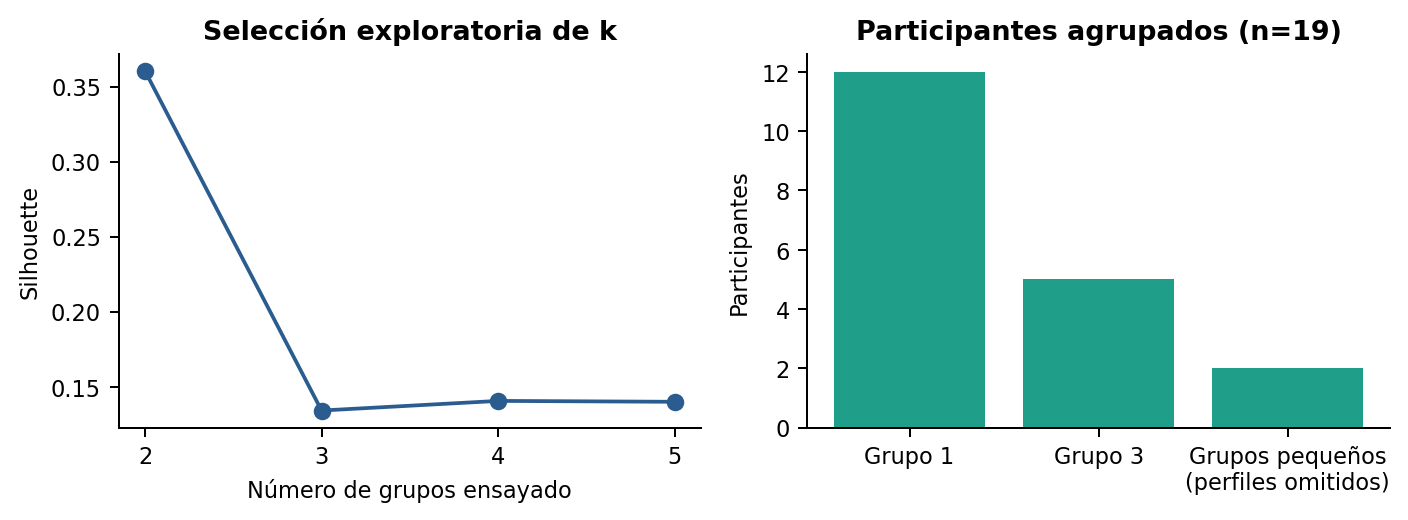

In [6]:
def tabla_busquedas(ajuste):
    filas = []
    for opcion in ajuste["busquedas"]:
        parametros = ", ".join(f"{nombre.removeprefix('modelo__')}={valor}"
                               for nombre, valor in opcion["parametros"].items())
        filas.append({
            "Búsqueda": opcion["metodo"],
            "Combinaciones": opcion["configuraciones"],
            "Configuración elegida": parametros,
            f"{ajuste['metrica']} media": opcion["media"],
            "Desv. entre pliegues": opcion["desviacion"],
            "Pliegues válidos": f"{opcion['pliegues_validos']}/{ajuste['n_folds']}",
        })
    return pd.DataFrame(filas).round(3)


c = r["clusters"]
if c["estado"] == "ok":
    comparacion = c["ajuste"]
    display(tabla_busquedas(comparacion))
    if comparacion["aplicado"]:
        print("Búsqueda elegida:", comparacion["mejor_metodo"])
    else:
        print("El ajuste por validación no produjo grupos utilizables. Se muestra el ensayo exploratorio.")
    print(f"Ajuste final: {c['k']} grupos con {c['n']} respuestas y silueta {c['silhouette']:.3f}.")
    print("Tamaños de los grupos:", ", ".join(str(tamano) for tamano in c["tamanos"].values()))
    print(f"Silueta descriptiva del agrupamiento jerárquico: {c['silhouette_jerarquico']:.3f}.")
    print(f"Varianza resumida por los dos primeros componentes de PCA: {100 * sum(c['pca_varianza']):.1f}%.")
    display(pd.Series(c["siluetas"], name="Silueta descriptiva en la muestra completa").rename_axis("Grupos").to_frame().round(3))
    display(Image(filename=str(OUT / "figuras" / "clusters.png")))
else:
    print("Muestra insuficiente para evaluar el agrupamiento.")

## 7. Supervisado: KNN para clasificar la modalidad de uso
La variable objetivo distingue el uso mixto (1) del uso exclusivo como guía o atajo (0). Las respuestas contextuales y las que quedaron sin clasificar salen de este ejercicio. La pregunta que define la etiqueta queda fuera de los predictores.

KNN asigna una categoría a partir de los casos de entrenamiento más cercanos. Ambas búsquedas prueban cuántos vecinos consultar, cómo medir la distancia y cuánto pesa cada vecino. Los pliegues conservan las proporciones de clase. Dentro de cada entrenamiento se vuelven a aprender escala, imputación y representación del texto.

Se elige la configuración con el mayor F1 medio de validación. F1 combina la precisión de las predicciones mixtas y la proporción de casos mixtos que se detectan. Después se comparan KNN y la referencia de la clase mayoritaria en la misma prueba reservada. La tabla secundaria reúne los modelos con ajustes fijos para mostrar la comparación original.

Entrenamiento: 16 | Prueba reservada: 6 | Pliegues: 5
Respuestas fuera de las dos clases: 2


,Búsqueda,Combinaciones,Configuración elegida,F1 media,Desv. entre pliegues,Pliegues válidos
0,GridSearchCV,16,"n_neighbors=3, p=1, weights=uniform",0.627,0.114,5/5
1,RandomizedSearchCV,8,"weights=distance, p=1, n_neighbors=3",0.560,0.285,5/5


Búsqueda elegida: GridSearchCV


,KNN ajustado,Referencia mayoritaria
Aciertos,0.833,0.667
Precisión,0.800,0.667
Recall,1.000,1.000
F1,0.889,0.800


,Predijo exclusivo,Predijo mixto
Real: exclusivo,1,1
Real: mixto,0,4


Comparación secundaria de modelos con ajustes fijos:


,modelo,cv_accuracy,cv_accuracy_sd,cv_f1,cv_f1_sd
0,Baseline (mayoría),0.567,0.149,0.713,0.132
1,Regresión logística,0.633,0.247,0.627,0.376
2,SVM,0.433,0.149,0.493,0.303
3,Random Forest,0.367,0.247,0.467,0.274
4,KNN,0.433,0.279,0.427,0.393


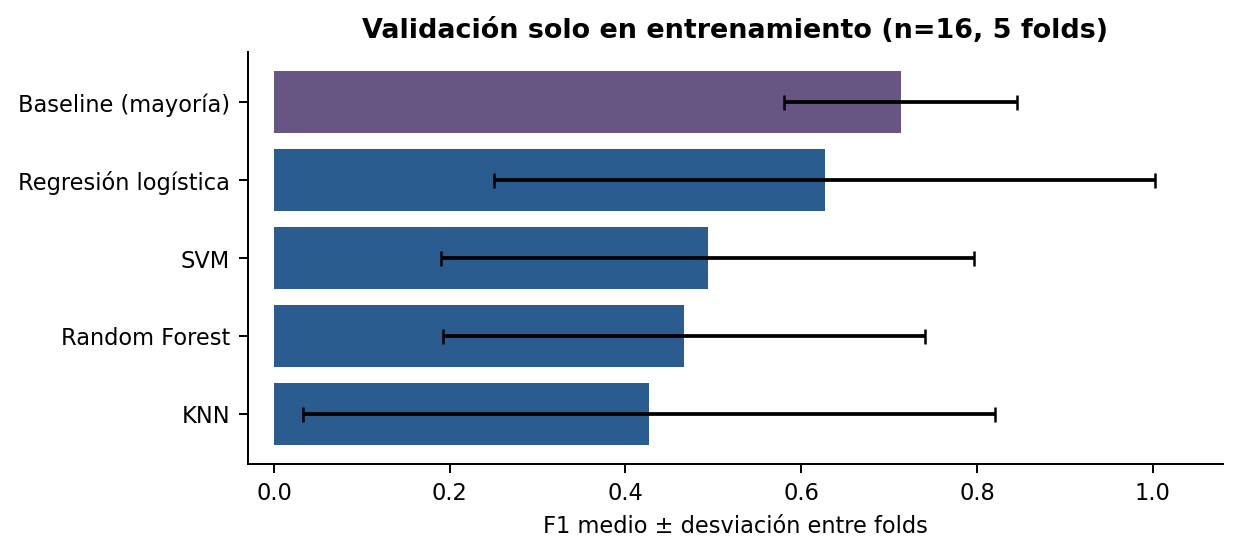

In [7]:
s = r["supervisado"]
if s["estado"] == "ok":
    print("Entrenamiento:", s["n_train"], "| Prueba reservada:", s["n_test"], "| Pliegues:", s["n_folds"])
    print("Respuestas fuera de las dos clases:", s["n_excluidos"])
    comparacion = s["ajuste"]
    display(tabla_busquedas(comparacion))
    print("Búsqueda elegida:", comparacion["mejor_metodo"])
    nombres = {"accuracy": "Aciertos", "precision": "Precisión", "recall": "Recall", "f1": "F1"}
    display(pd.DataFrame({
        "KNN ajustado": {etiqueta: comparacion["test"][metrica] for metrica, etiqueta in nombres.items()},
        "Referencia mayoritaria": {etiqueta: s["baseline_test"][metrica] for metrica, etiqueta in nombres.items()},
    }).round(3))
    display(pd.DataFrame(comparacion["test"]["confusion"],
                         index=["Real: exclusivo", "Real: mixto"],
                         columns=["Predijo exclusivo", "Predijo mixto"]))
    print("Comparación secundaria de modelos con ajustes fijos:")
    display(pd.DataFrame(s["cv"]).drop(columns="fold_f1").round(3))
    display(Image(filename=str(OUT / "figuras" / "modelos_cv.png")))
else:
    print(s["motivo"])

## 8. Regresión: estimación de las horas de IA
Este ejercicio usa una variable numérica disponible: horas diarias declaradas. Los predictores son semestre de inicio y cantidad de herramientas. La regresión lineal se compara con una referencia que siempre predice la media de entrenamiento.

La partición de esta tarea reserva seis de los 24 casos para prueba y usa 18 para entrenamiento, con semilla 42. Cinco pliegues sobre entrenamiento evalúan estabilidad. Ambos modelos se fijaron antes de consultar la prueba y no se ajustaron parámetros buscando un R² favorable.

**R² = 1 − SSE/SST:** compara el error cuadrático con la variación respecto de la media del conjunto evaluado. Puede ser negativo y no es un porcentaje de precisión. La referencia usa la media de entrenamiento, así que también puede tener R² negativo en prueba.

**MAE** expresa la desviación absoluta media en horas; **RMSE** da más peso a errores grandes y también se expresa en horas. Los pliegues con horas constantes conservan R² nulo. El resumen CV es una media por pliegue, sin reunir predicciones para calcular un único R².

Casos completos: 24 | Excluidos: 0
Entrenamiento: 18 | Prueba: 6


,Modelo,R² prueba,MAE (horas),RMSE (horas)
0,Regresión lineal,-0.245,0.808,1.039
1,Referencia (media),-0.064,0.634,0.961


,Modelo,r2_media,r2_sd,mae_media_h,rmse_media_h,folds_r2_validos
0,Regresión lineal,-3.110,3.603,1.559,1.983,5
1,Referencia (media),-2.352,4.011,1.322,1.751,5


CV resume los resultados por pliegue. Con tres o cuatro casos por pliegue, R² puede variar mucho.
El MAE de 0.808 horas representa unos 48 minutos de error medio, no un margen garantizado por persona.
El ejercicio estima intensidad declarada de uso de IA; no predice calificaciones.


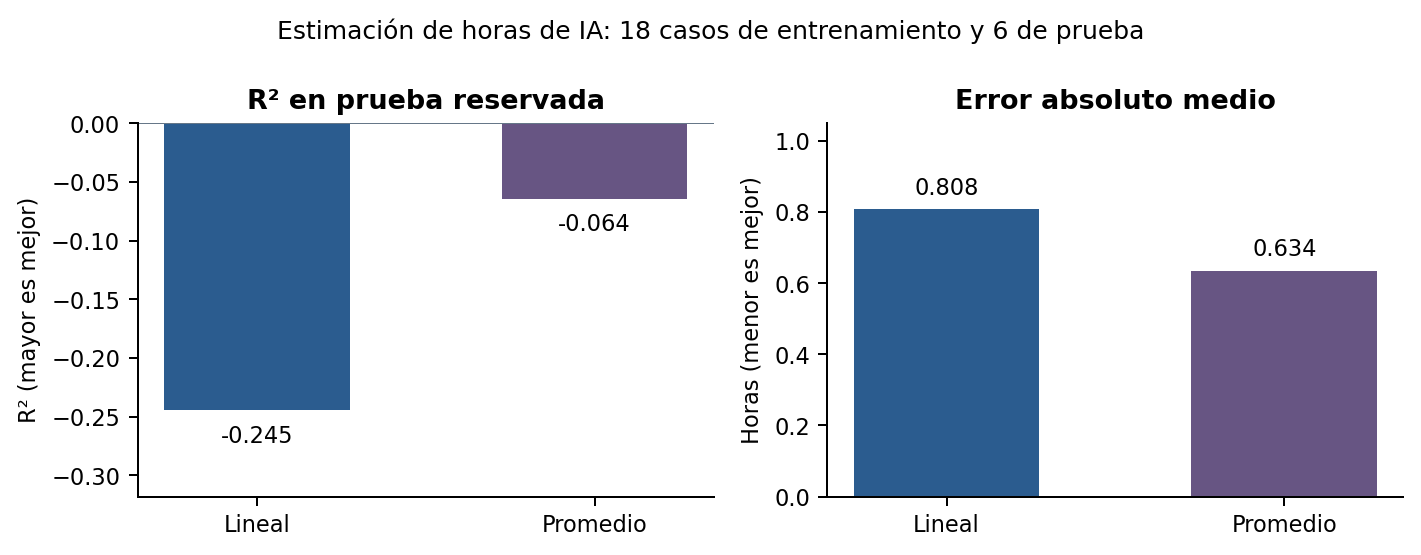

In [8]:
g = r["regresion"]
if g["estado"] == "ok":
    print("Casos completos:", g["n"], "| Excluidos:", g["n_excluidos"])
    print("Entrenamiento:", g["n_train"], "| Prueba:", g["n_test"])
    tabla_prueba = pd.DataFrame([{"Modelo": m["modelo"], **m["prueba"]} for m in g["modelos"]])
    display(tabla_prueba.rename(columns={"r2":"R² prueba", "mae_h":"MAE (horas)", "rmse_h":"RMSE (horas)"}).round(3))
    display(pd.DataFrame([{"Modelo": m["modelo"], **m["cv"]} for m in g["modelos"]]).round(3))
    print("CV resume los resultados por pliegue. Con tres o cuatro casos por pliegue, R² puede variar mucho.")
    mae = next(m for m in g["modelos"] if m["modelo"] == "Regresión lineal")["prueba"]["mae_h"]
    print(f"El MAE de {mae:.3f} horas representa unos {60*mae:.0f} minutos de error medio, no un margen garantizado por persona.")
    print("El ejercicio estima intensidad declarada de uso de IA; no predice calificaciones.")
    display(Image(filename=str(OUT / "figuras" / "regresion.png")))
else:
    print(g["motivo"])

## 9. Qué podemos concluir de esta ejecución
Las cifras se obtienen del mismo análisis que produce los agregados del tablero y de los informes. El EDA describe al grupo. K-Means explora similitudes entre respuestas. KNN predice categorías declaradas y la regresión estima horas de uso. Cada resultado tiene una pregunta y una base distintas.

In [9]:
k = r["kpis"]
print(f"Uso híbrido declarado: {k['hibrido_pct']:.1f}%.")
print(f"Guía o híbrido: {k['guia_hibrido_pct']:.1f}%.")
print(f"Al menos dos herramientas: {k['multiherramienta_pct']:.1f}%.")
print(f"Mediana de uso: {k['mediana_ia_h']:.2f} horas al día.")
if c["estado"] == "ok":
    print(f"Exploración de K-Means: {c['k']} grupos en {c['n']} respuestas con silueta {c['silhouette']:.3f}.")
if s["estado"] == "ok":
    print(f"F1 en prueba: KNN ajustado {s['ajuste']['test']['f1']:.3f}, referencia {s['baseline_test']['f1']:.3f}.")
    print(f"Un acierto en prueba cambia la proporción de aciertos en {s['test_sensible_pp']:.1f} puntos porcentuales.")
if g["estado"] == "ok":
    lineal = next(m for m in g["modelos"] if m["modelo"] == "Regresión lineal")["prueba"]
    referencia = next(m for m in g["modelos"] if m["modelo"] == "Referencia (media)")["prueba"]
    print(f"Regresión: R² de prueba = {lineal['r2']:.3f} y MAE = {lineal['mae_h']:.3f} horas.")
    if lineal["mae_h"] >= referencia["mae_h"]:
        print("El promedio de entrenamiento quedó más cerca de las horas declaradas en esta prueba.")
print("Las encuestas describen experiencias. Para estudiar el rendimiento hacen falta resultados académicos independientes.")
display(pd.Series(r["proveniencia"]["versiones"], name="Versión").to_frame())

Uso híbrido declarado: 54.2%.
Guía o híbrido: 83.3%.
Al menos dos herramientas: 54.2%.
Mediana de uso: 1.50 horas al día.
Exploración de K-Means: 4 grupos en 19 respuestas con silueta 0.110.
F1 en prueba: KNN ajustado 0.889, referencia 0.800.
Un acierto en prueba cambia la proporción de aciertos en 16.7 puntos porcentuales.
Regresión: R² de prueba = -0.245 y MAE = 0.808 horas.
El promedio de entrenamiento quedó más cerca de las horas declaradas en esta prueba.
Las encuestas describen experiencias. Para estudiar el rendimiento hacen falta resultados académicos independientes.


,Versión
pandas,2.2.3
numpy,2.2.6
scikit-learn,1.6.1
scipy,1.15.3
matplotlib,3.10.7
